## **로지스틱 회귀**
### Classification 문제
    - 학습 데이터의 특성과 관계 등을 학습한 후, 미지의 입력 데이터에 대해서 어떤 종류의 값으로 분류될 수 있는지 예측
    - 예
        - 스팸 메일 분류
        - 암 판별
- 라벨링이 된 학습 데이터 -> 학습 -> 테스트 데이터
### 이진 분류 문제
- 먼저 전체 임의의 W, b에 대해 임의의 회귀 직선을 구함
- 주어진 데이터 x가 1이라면 y = 양수, 0이라면 y = 음수가 나오도록 직선을 수정 -> 분류
- 시그모이드 함수(Activation), (음수와 양수를 적당한 확률 값으로 바꿔줌)
- 학습 데이터의 특성과 분포를 나타내는 최적의 직선을 찾고
    - 그 직선을 기준으로 미지의 데이터를 0 또는 1로 분류하는 알고리즘
- 정확도가 높아 신경망의 기본 Neuron으로 사용

### Sigmoid 함수
- z = Wx + b에 대해 역함수를 취함
- x를 넣으면 그에 맞는 확률이 나옴

### likelyhood 함수
- 각 입력 x에 대해 t = 1일 경우, 1일 호가률이 높고, t = 0일 경우, 0일 확률이 높을 수록 0, 1 분류가 잘 될 가능성이 높음. 따라서 이 우도 함수 값이 커지도록 W와 b를 업데이터
$$L(W,b) = \prod^n_{i = 1}p(C = t_i | x_i) = \prod^n_{i=1}y_i^{t_i}(1-y_i)^{1-t_i}$$

### Cross Entropy
- 함수값이 최대값이 되는 것을 알기 위해서는 W, b에 대해 편미분이 필요, 곱하기는 미분이 불편 -> log를 취해 덧셈으로 바꾸고, 함수의 부호를 바꾸면 최대화 문제 -> 최소화 문제로 바뀜
$$E(W,b) = -\frac1n\sum^n_{i=1}[t_i \log y_i + (1-t_i) \log(1-y_i)]$$
$$W = W-\alpha\frac{\partial E(W, b)}{\partial W}$$
$$b = b-\alpha\frac{\partial E(W, b)} {\partial b}$$

# 신경망의 시작
- 선형회귀로 and, or, not, nand는 구현이 가능
- xor은 선형회귀로 구분이 불가
- Multi-layer 구조로 구현이 가능
    - 각각의 뉴런들은 로지스틱 회귀로 잘 작동
    - xor은 여러 논리 게이트로 구성이 가능
    - 입력은 화살표 방향으로 들어가며, 이전층 뉴런들의 출력은 다음 층 뉴런의 입력으로 사용됨 -> Neural networt
    - 학습 알고리즘으로 Error-Backpropagation 알고리즘
    - 최근 딥러닝의 핵심 기술

In [6]:
import numpy as np

def sigmoid(x):
    return 1 / (1+np.exp(-x))

def cross_entropy(t, y):    # 크로스 엔트로피 함수
    delta = 1e-7            # log함수의 음수 무한대 발산 방지
    return -np.sum(t*np.log(y + delta) + (1-t)*np.log((1 - y)+delta))

def lossFunc():
    z = np.dot(x_data, W) + b    # 선형회귀 후 -->
    y = sigmoid(z)               # 시그모이드
    return cross_entropy(t_data, y)

def numerical_derivative(fn, param):    # 주어진 함수 fn에 대한 W 또는 b에 대한 수치미분
    delta = 1e-4  # 0.0001          # 실제 미분함수를 구하지 않고 특정 W, b의 +/- 0.0001 범위에서 기울기 구함
    grad = np.zeros_like(param)     # 주어진 각 W 또는 b들에 대한 기울기 값 저장

    it = np.nditer(param, flags=['multi_index'], op_flags=['readwrite'])  # 다차원 배열 원소들의 순서참조 지원 함수
    while not it.finished:
        idx = it.multi_index
        temp = param[idx]            # 주어진 W, b값(기울기 대상지점값)을 저장해두고 기울기 계산 후 다시 원상태로 되돌림

        param[idx] = temp + delta
        loss1 = fn()           # W 또는 b의 약간의 증가치(+0.0001)에 대한 손실함수 값
        param[idx] = temp - delta
        loss2 = fn()           # W 또는 b의 약간의 감소치(+0.0001)에 대한 손실함수 값

        grad[idx] = (loss1-loss2) / (2*delta)    # 주어진 W, b의 미세한 구간에서의 손실함수값의 변화량 --> 기울기

        param[idx] = temp            # 기울기값 계산시 사용된 주어진 값의 사용이 끝난뒤 원래 값으로 되돌린다.
        it.iternext()
    return grad

def grad_descent(learning_rate, repeat, outStep):
    global W, b

    print("Initial error value = {:.3f}".format(lossFunc()))
    # print("Initial W = ", W.flatten().round(3))
    # print("Initial b = ", b.round(3))
    for step in range(repeat+1):        # 적당한 횟수만큼 경사하강 반복
        W -= learning_rate * numerical_derivative(lossFunc, W)
        b -= learning_rate * numerical_derivative(lossFunc, b)

        if (step % outStep == 0):       # 경사하강 반복 중간마다 손실값 출력
            print("Step = {:>6d}".format(step), "\tError Value = {:.4f}".format(lossFunc()),
                  "\tW =", W.flatten().round(3), "\tb = ", b.round(3))

def predict(x):
    z = np.dot(x,W) + b
    y = sigmoid(z)
    # result = (y > 0.5)*1
    return y    # y.round(4), result

## 로지스틱 회귀 예시1

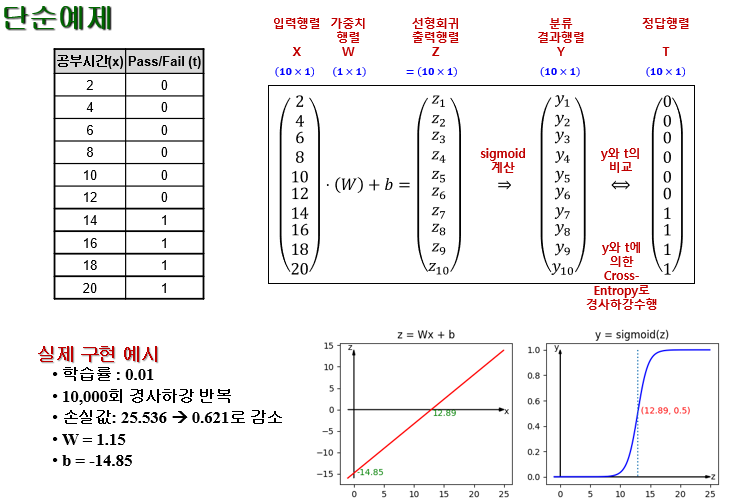

In [7]:
x_data = np.array([2, 4, 6, 8, 10, 12, 14, 16, 18, 20]).reshape(10, 1)
t_data = np.array([0, 0, 0, 0,  0,  0,  1,  1,  1,  1]).reshape(10, 1)

W = np.random.rand(1, 1)  # 1X1 행렬
b = np.random.rand(1)

learning_rate = 1e-2  # 0.1, 0.01, 0.05, 0.001 일 때의 손실함수 값 비교
repeat = 10000
outStep = repeat/20     # 1000

grad_descent(learning_rate, repeat, outStep)

Initial error value = 42.372
Step =      0 	Error Value = 24.8028 	W = [0.524] 	b =  [0.414]
Step =    500 	Error Value = 2.2072 	W = [0.351] 	b =  [-4.656]
Step =   1000 	Error Value = 1.6234 	W = [0.497] 	b =  [-6.227]
Step =   1500 	Error Value = 1.3828 	W = [0.58] 	b =  [-7.323]
Step =   2000 	Error Value = 1.2324 	W = [0.645] 	b =  [-8.189]
Step =   2500 	Error Value = 1.1263 	W = [0.7] 	b =  [-8.918]
Step =   3000 	Error Value = 1.0457 	W = [0.748] 	b =  [-9.553]
Step =   3500 	Error Value = 0.9814 	W = [0.791] 	b =  [-10.119]
Step =   4000 	Error Value = 0.9285 	W = [0.83] 	b =  [-10.633]
Step =   4500 	Error Value = 0.8838 	W = [0.866] 	b =  [-11.106]
Step =   5000 	Error Value = 0.8452 	W = [0.9] 	b =  [-11.545]
Step =   5500 	Error Value = 0.8114 	W = [0.931] 	b =  [-11.956]
Step =   6000 	Error Value = 0.7815 	W = [0.96] 	b =  [-12.343]
Step =   6500 	Error Value = 0.7547 	W = [0.988] 	b =  [-12.709]
Step =   7000 	Error Value = 0.7304 	W = [1.015] 	b =  [-13.057]
Step =   7

In [8]:
predict([[12], [13], [23]])

array([[0.26338978],
       [0.53108838],
       [0.99999131]])

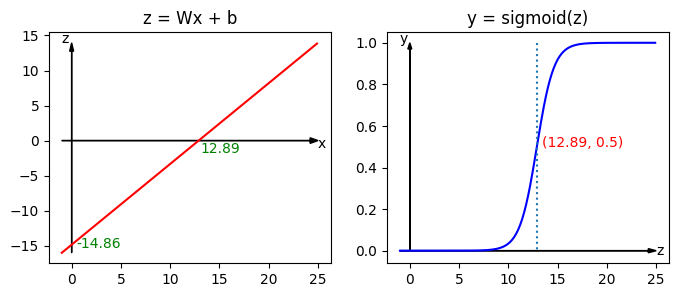

In [9]:
import matplotlib.pyplot as plt

def sigmoid(x): # 시그모이드 함수 정의
    return 1/(1+np.exp(-x))

x_min, x_max = -1., 25.             # x축 범위
Ws, bs = W.item(), b.item()     # W, b의 스칼라 값
y_min = x_min*Ws + bs
y_max = x_max*Ws + bs

x = np.arange(x_min, x_max, 0.1)
z = x*Ws + bs
y = sigmoid(z)
half = -bs/Ws   # x축 경계값

plt.figure(figsize=(8, 3))

plt.subplot(1,2, 1)
plt.plot(x, z, 'r')

plt.arrow(x_min, 0, x_max-x_min, 0, head_width=0.8, head_length=0.8, color='black', length_includes_head=True)
plt.arrow(0, y_min, 0, y_max-y_min, head_width=0.4, head_length=1.2, color='black', length_includes_head=True)
plt.text(x_min, x_max*Ws + bs, 'z', color='k')
plt.text(x_max, 0-1, 'x', color='k')

plt.text(half+0.2, 0-1.7, '{}'.format(round(half, 2)), color='g')
plt.text(0+0.5, bs-0.5, '{}'.format(round(bs, 2)), color='g')
plt.title('z = Wx + b')


plt.subplot(1,2, 2)
plt.arrow(x_min, 0, x_max-x_min, 0, head_width=0.02, head_length=0.8, color='black', length_includes_head=True)
plt.arrow(0, 0, 0, 1, head_width=0.4, head_length=0.03, color='black', length_includes_head=True)
plt.text(x_max, -0.02, 'z', color='k')
plt.text(-1, 1, 'y', color='k')

plt.plot(x, y, 'b')
plt.plot([half, half],[1.0,0.0], ':') # 가운데 점선 추가
plt.text(half+0.5, 0.5, '({}, 0.5)'.format(round(half, 2)), color='r')
plt.title('y = sigmoid(z)')
plt.show()

## 로지스틱 회귀 예시2

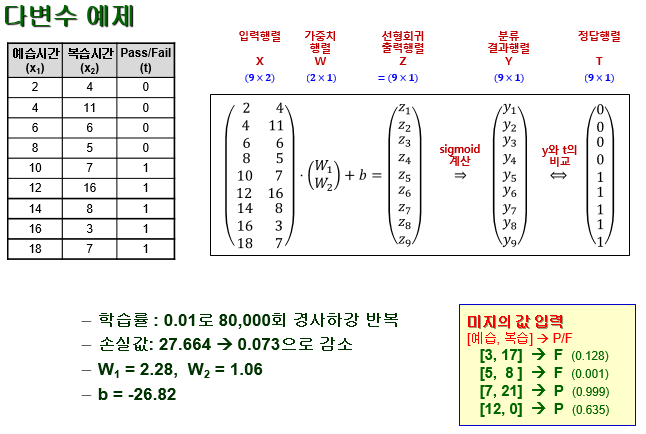

In [10]:
x_data = np.array([ [2, 4], [4, 11], [6, 6], [8, 5], [10, 7], [12, 16], [14, 8], [16, 3], [18, 7] ])
t_data = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1]).reshape(9, 1)

W = np.random.rand(2, 1)  # 2X1 행렬
b = np.random.rand(1)

learning_rate = 1e-2  # 0.1, 0.01, 0.05, 0.001 일 때의 손실함수 값 비교
repeat = 80000
outStep = repeat/20     # 2000

grad_descent(learning_rate, repeat, outStep)

Initial error value = 24.351
Step =      0 	Error Value = 13.7328 	W = [ 0.587 -0.041] 	b =  [0.695]
Step =   4000 	Error Value = 0.6826 	W = [0.96  0.128] 	b =  [-9.306]
Step =   8000 	Error Value = 0.4648 	W = [1.198 0.253] 	b =  [-12.224]
Step =  12000 	Error Value = 0.3592 	W = [1.349 0.366] 	b =  [-14.266]
Step =  16000 	Error Value = 0.2932 	W = [1.467 0.46 ] 	b =  [-15.884]
Step =  20000 	Error Value = 0.2476 	W = [1.565 0.537] 	b =  [-17.229]
Step =  24000 	Error Value = 0.2141 	W = [1.649 0.603] 	b =  [-18.381]
Step =  28000 	Error Value = 0.1885 	W = [1.724 0.659] 	b =  [-19.389]
Step =  32000 	Error Value = 0.1683 	W = [1.79  0.709] 	b =  [-20.284]
Step =  36000 	Error Value = 0.1520 	W = [1.85  0.753] 	b =  [-21.089]
Step =  40000 	Error Value = 0.1385 	W = [1.905 0.793] 	b =  [-21.821]
Step =  44000 	Error Value = 0.1272 	W = [1.955 0.83 ] 	b =  [-22.49]
Step =  48000 	Error Value = 0.1176 	W = [2.001 0.864] 	b =  [-23.108]
Step =  52000 	Error Value = 0.1093 	W = [2.044 0

In [11]:
#                    예습, 복습
test_data = np.array([[3, 17],  # Fail : 0
                      [5, 8],   # Fail : 0
                      [7, 21],  # Pass : 1
                      [12, 0]]) # Pass : 1
predict(test_data).round(3)

array([[0.129],
       [0.001],
       [1.   ],
       [0.635]])

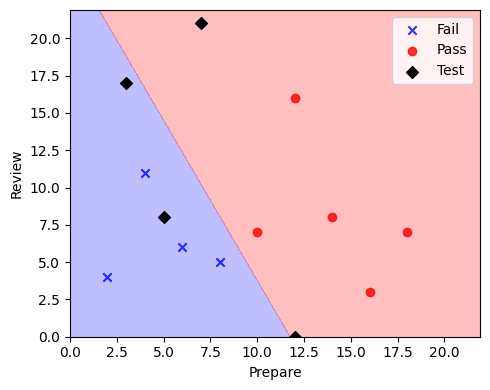

In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

x1min, x1max = 0, 22
x2min, x2max = 0, 22
xx1, xx2 = np.meshgrid(np.arange(x1min, x1max, 0.1),
                       np.arange(x2min, x2max, 0.1))
xy_data = np.array([xx1.ravel(), xx2.ravel()]).T
Z = predict(xy_data)  # meshgrid 모든 교차점에 대한 predict 값
Z = Z.reshape(xx1.shape)

failpass = ('Fail', "Pass")
markers = ('x', 'o')
colors = ('blue', 'red')
cmap = ListedColormap(colors) #[:len(np.unique(t_data))])

plt.figure(figsize=(5,4))

plt.contourf(xx1, xx2, Z, levels=1, alpha=0.25, cmap=cmap)

plt.xlim(xx1.min(), xx1.max())
plt.ylim(xx2.min(), xx2.max())

for idx, cl in enumerate(np.unique(t_data)):
    plt.scatter(x=x_data[t_data.flatten() == cl, 0], y=x_data[t_data.flatten() == cl, 1],
                alpha=0.8, c=colors[idx],
                marker=markers[idx], label=failpass[cl]) #, edgecolor='b')

plt.scatter(test_data[:,0], test_data[:,1], c='k',
            marker='D', label='Test')

plt.xlabel('Prepare')
plt.ylabel('Review')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## **`np.meshgrid`** 테스트

In [13]:
x = np.array([1, 2, 3, 4])
y = np.array([5, 6, 7])

X, Y = np.meshgrid(x, y)    # X는 y 데이터에 대응하는 x축 인덱스 나열
                            # Y는 x 데이터에 대응하는 y축 인덱스 나
print('X = \n', X)
print('Y = \n', Y)
print('X 펼침 =', X.flatten())
print('Y 펼침 =', Y.flatten())
                        # 1차원 배열 2개로 2차원 배열 ->  전치하면 -> 2쌍 입력 데이터 생성

XY_grid_data = np.stack([X.ravel(), Y.ravel()], axis=1)
# XY_grid_data = np.array([X.ravel(), Y.ravel()]).T # 는 위와 동일
print('(x,y) 쌍의 입력 형태 = \n', XY_grid_data)

Z = np.array([ c[0]*c[1] for c in np.array([X.ravel(), Y.ravel()]).T])
print("(x,y) 쌍의 연산 결과 =", Z)
Z = Z.reshape(X.shape)
# Z = X * Y  # 실제는 이과정과 동일함
print("(x,y) 쌍의 연산 결과를 격자형태로 변경\n", Z)

X = 
 [[1 2 3 4]
 [1 2 3 4]
 [1 2 3 4]]
Y = 
 [[5 5 5 5]
 [6 6 6 6]
 [7 7 7 7]]
X 펼침 = [1 2 3 4 1 2 3 4 1 2 3 4]
Y 펼침 = [5 5 5 5 6 6 6 6 7 7 7 7]
(x,y) 쌍의 입력 형태 = 
 [[1 5]
 [2 5]
 [3 5]
 [4 5]
 [1 6]
 [2 6]
 [3 6]
 [4 6]
 [1 7]
 [2 7]
 [3 7]
 [4 7]]
(x,y) 쌍의 연산 결과 = [ 5 10 15 20  6 12 18 24  7 14 21 28]
(x,y) 쌍의 연산 결과를 격자형태로 변경
 [[ 5 10 15 20]
 [ 6 12 18 24]
 [ 7 14 21 28]]


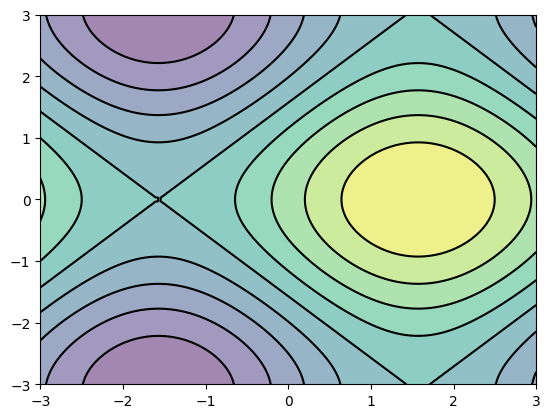

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 예시 데이터
xx = np.linspace(-3, 3, 100)
yy = np.linspace(-3, 3, 100)
XX, YY = np.meshgrid(xx, yy)
Z = np.sin(XX) + np.cos(YY)  # 예시 Z값

fig, ax = plt.subplots()

# contourf로 채우기
ax.contourf(XX, YY, Z, levels=10, cmap='viridis', alpha=0.5)

# contour로 경계선 그리기
ax.contour(XX, YY, Z, levels=10, colors='k', linestyles='-')

plt.show()